# Imports

In [1]:
import sys
import pandas as pd
import os
import numpy as np
import plotly.io as pio
import plotly.express as px
import math
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns
sys.path.append('..')
from plotly.graph_objs import Figure
from functools import reduce
from definitions import ROOT_DIR, DATA_DIR

# Utils

In [2]:
FIGURES_DIR = os.path.join(ROOT_DIR, 'assets', 'corpus_statistics')
os.makedirs(FIGURES_DIR, exist_ok=True)

In [3]:
pio.templates.default = "seaborn"

In [4]:
def save_fig(fig : Figure, filename : str) -> None:
    fig.write_image(os.path.join(FIGURES_DIR, filename))

def show(fig : Figure) -> None:
    fig.update_layout(font_size = 12)
    fig.show()

# Corpus

- Load the data

In [5]:
config = 'nantes-uni-2020'
data_path = os.path.join(DATA_DIR, config, 'annotate', 'data.jsonl')
data = pd.read_json(data_path, lines=True)
data['labled'] = data['labels'].apply(lambda x : len(x) > 0)

In [6]:
data.head()

,id,title,abstract,keywords,authors,venues,teams,date,labels,labled
0,5420658,Machine Learning Based Environmental Impact Pr...,The construction sector significantly contribu...,"[environment product declaration, life cycle a...","[Bishwash Neupane, Benoit Hilloulin, Raphael C...","[spi.gciv.ec, info.info-ia, info.info-lg, sde.ie]","[GEM, LS2N]",2026-11-21 00:00:00+00:00,"[Eco-design, Industrial Digitalization]",True
1,5562561,TWO-DIMENSIONAL INFRARED EMISSIVITY OF A SEA S...,The sea surface intrinsic infrared emission is...,"[modeling, sea surface, infrared emissivity]","[Léa Ould-Ahmed, Christophe Bourlier, Nicolas ...","[spi.tron, spi, spi.other]",[IETR],2026-08-09 00:00:00+00:00,[],False
2,5556678,Vision and Attention-Based Models for Process ...,Abstract . Anomaly detection is a fundamental ...,"[computer vision, process control, attention m...","[Yunfan Li, Elodie Paquet, Sébastien Levilly, ...","[info.info-cv, info.info-ai, info.info-ti, spi...",[LS2N],2026-07-08 00:00:00+00:00,"[Robotics, Processes and Assembly, Additive Ma...",True
3,5554251,Exponential stabilization of two coupled linea...,This work addresses the stabilization problem ...,"[korteweg de vries system, backstepping, expon...","[Youssef Khalifeh, Ihab Haidar, Jean-Pierre Ba...","[spi, math]",[LS2N],2026-07-07 00:00:00+00:00,[],False
4,5559591,Load-dependent travel time estimation for carg...,This work addresses an extension of the pickup...,[city logistics vehicle routing metaheuristics],"[Fabien Lehuédé, Awen Jacq-Baudet, Leandro Mon...",[info.info-ro],[LS2N],2026-07-06 00:00:00+00:00,"[Decarbonization of Mobility, Industrial Organ...",True


- By Year

In [7]:
fig = px.bar(
    data_frame=data['date'].apply(lambda x : int(str(x)[:4]))
        .value_counts()
        .reset_index()
        .rename(columns={ "date" : "Year", "count" : "Number Of Articles" }),
    x="Year",
    y="Number Of Articles",
    text = "Number Of Articles",
    width=800,
    height=550
)

save_fig(fig, 'year_distribution.pdf')
show(fig)

In [8]:
fig = px.bar(
    data_frame=data[data['labled']]['date'].apply(lambda x : int(str(x)[:4]))
        .value_counts()
        .reset_index()
        .rename(columns={ "date" : "Year", "count" : "Number Of Articles" }),
    x="Year",
    y="Number Of Articles",
    text = "Number Of Articles",
    width=800,
    height=550
)

save_fig(fig, 'year_distribution_labled_only.pdf')
show(fig)

- Keywords

In [9]:
keywords = reduce(lambda a,b : a + b, data['keywords'])
keywords = list(map(str.lower, keywords))
index, count = np.unique(keywords,return_counts=True)
keywords = pd.Series(index=index,data=count).sort_values(ascending=False)
print(len(keywords))

17515


In [10]:
fig = px.bar(
    data_frame = keywords.iloc[:13].sort_values(ascending=True).reset_index(),
    y = "index",
    x = 0,
    text = 0,
    width=800,
    height=450
)
fig.update_layout(xaxis_title="Frequency",yaxis_title="Keyword")
save_fig(fig, 'top_10_most_frequent_keywords.pdf')
show(fig)

- Categories

In [11]:
sub_categories = reduce(lambda a,b : a + b, data['venues'])
sub_categories = pd.Series(sub_categories).value_counts()
categories = sub_categories.groupby(by=lambda x : x.split('.')[0]).sum().sort_values(ascending=False)
categories

spi     4272
info    3469
chim    1286
phys    1003
sdv      929
shs      760
sde      307
math     266
stat     137
scco     102
sdu       87
qfin      57
nlin      24
Name: count, dtype: int64

In [12]:
fig = px.bar(
    data_frame = categories.sort_values(ascending=True).reset_index(),
    y = "index",
    x = "count",
    text = "count",
    width=800,
    height=450
)
fig.update_layout(xaxis_title="Frequency",yaxis_title="Category")
save_fig(fig, 'top_10_most_frequent_categories.pdf')
show(fig)

- Teams

In [13]:
teams = list(set(reduce(lambda a,b : a + b, data["teams"])))
# teams.remove('LS2N')

for team in teams:
    data[team] = data["teams"].apply(lambda x : team in x)

In [14]:
fig = px.bar(
    data_frame = data[teams]
        .sum()
        .reset_index()
        .rename(columns = { "index" : "Team", 0 : "Number Of Articles" })
        .sort_values(by = "Number Of Articles"),
    y = "Team",
    x = "Number Of Articles",
    text = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'teams_distribution.pdf')
fig.show()

In [25]:
fig = px.pie(
    data_frame = data[data['labled']][teams]
        .sum()
        .reset_index()
        .rename(columns = { "index" : "Team", 0 : "Number Of Articles" })
        .sort_values(by = "Number Of Articles"),
    names = "Team",
    values = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'teams_distribution_labeld_only.pdf')
fig.show()

- DSIs

In [35]:
data['labels'].apply(lambda x : len(x) > 0).value_counts()

labels
True     5301
False    2975
Name: count, dtype: int64

In [20]:
# classified Vs Not classified
fig = px.pie(
    names = ['Labeled', 'Not labeled'],
    values = data['labels'].apply(lambda x : len(x) > 0).value_counts(),
    width = 850,
    height = 600
)

save_fig(fig, "labeled.pdf")
show(fig)

In [21]:
# Number of Labels
labels = reduce(lambda a, b : a+b, data['labels'].tolist())
labels = pd.Series(labels).value_counts()
labels.reset_index()

,index,count
0,Composites and New Materials,1948
1,Industrial Digitalization,1717
2,Monitoring and Analysis,1407
3,Digital Engineering of Products and Processes,1297
4,Industrial Organization Performance,733
5,Processes and Assembly,588
6,Eco-responsible Processes,557
7,Robotics,510
8,Decarbonization of Energy,401
9,Augmentation of Human Capabilities in Manufact...,250


In [24]:
fig = px.pie(
    data_frame = labels
        .sort_values()
        .reset_index()
        .rename(columns={ 'index' : 'DSI', 'count' : 'Number Of Articles' }),
    names = "DSI",
    values = "Number Of Articles",
    # text = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'dsis_distribution.pdf')
show(fig)

- Team By Domain :

In [40]:
teams_labels = []

for idx, row in data.iterrows():

    for team in row['teams']:

        # if team == 'LS2N':
        #     continue

        for label in row['labels']:
            teams_labels.append({ "team" : team, "label" : label })

teams_labels = pd.DataFrame(teams_labels)
teams_labels = teams_labels[['team', 'label']].value_counts().reset_index()

In [44]:
teams_labels[teams_labels['team'] == 'LS2N']

,team,label,count
0,LS2N,Industrial Digitalization,878
3,LS2N,Industrial Organization Performance,540
4,LS2N,Digital Engineering of Products and Processes,508
6,LS2N,Robotics,469
7,LS2N,Monitoring and Analysis,449
15,LS2N,Augmentation of Human Capabilities in Manufact...,214
18,LS2N,Processes and Assembly,179
19,LS2N,User-Centered Design,167
30,LS2N,Decarbonization of Energy,86
44,LS2N,Decarbonization of Mobility,52


In [ ]:
fig = px.bar(
    data_frame = teams_labels,
    x = "count",
    y = "team",
    color = "label",
    width = 1200,
    height = 600,
)

fig.update_layout(barmode='stack', yaxis={'categoryorder':'total ascending'})
fig.update_layout(xaxis_title = "Number of Articles", yaxis_title = "Team")

save_fig(fig, 'teams_by_sub_domain.pdf')
show(fig)

In [ ]:
# 1. Setup grid dimensions
teams = teams_labels['team'].unique()
n_teams = len(teams)
cols = 1  # Set how many columns you want
rows = math.ceil(n_teams / cols)

# 2. Initialize the subplot figure
# 'specs' must be set to 'type': 'domain' for pie charts
fig = make_subplots(
    rows=rows, 
    cols=cols, 
    subplot_titles=teams,
    specs=[[{'type': 'domain'}] * cols] * rows
)

# 3. Add traces in a loop
for i, label in enumerate(teams):
    row = (i // cols) + 1
    col = (i % cols) + 1
    
    # Filter data
    df_sub = teams_labels[teams_labels['team'] == label]
    
    # Add the pie trace
    fig.add_trace(
        go.Pie(
            labels=df_sub['label'],
            values=df_sub['count'],
            name=label
        ),
        row=row, col=col
    )

# 4. Finalize layout
fig.update_layout(
    height=400 * rows,  # Adjust height based on rows
    width=850,
    title_text="Team Label Distributions",
    showlegend=True
)

fig.show()

In [53]:
fig = px.bar(
    data_frame = teams_labels,
    x = "count",
    y = "label",
    color = "team",
    width = 1200,
    height = 600
)
fig.update_layout(barmode='stack', yaxis={'categoryorder':'total ascending'})
fig.update_layout(xaxis_title = "Number of Articles", yaxis_title = "Sub-Domain")
save_fig(fig, 'sub_domains_by_team.pdf')
show(fig)

In [56]:
# 1. Setup grid dimensions
labels = teams_labels['label'].unique()
n_labels = len(teams)
cols = 2  # Set how many columns you want
rows = math.ceil(n_labels / cols)

# 2. Initialize the subplot figure
# 'specs' must be set to 'type': 'domain' for pie charts
fig = make_subplots(
    rows=rows, 
    cols=cols, 
    subplot_titles=labels,
    specs=[[{'type': 'domain'}] * cols] * rows
)

# 3. Add traces in a loop
for i, label in enumerate(labels):

    row = (i // cols) + 1
    col = (i % cols) + 1
    
    # Filter data
    df_sub = teams_labels[teams_labels['label'] == label]
    
    # Add the pie trace
    fig.add_trace(
        go.Pie(
            labels=df_sub['team'],
            values=df_sub['count'],
            name=label
        ),
        row=row, col=col
    )

# 4. Finalize layout
fig.update_layout(
    height=400 * rows,  # Adjust height based on rows
    width=850,
    title_text="Team Label Distributions",
    showlegend=True
)

fig.show()

In [57]:
labels = teams_labels['label'].unique().tolist()
cooccurence_matrix = np.zeros((len(labels), len(labels)))

for i,label_i in enumerate(labels):
    for j,label_j in enumerate(labels):

        mask_i = data['labels'].apply(lambda x : label_i in x)
        mask_j = data['labels'].apply(lambda x : label_j in x)

        p_j_knowing_i = mask_j[mask_i].mean()
        cooccurence_matrix[i, j] = p_j_knowing_i

cooccurence_matrix = pd.DataFrame(data=cooccurence_matrix, index=labels, columns=labels)

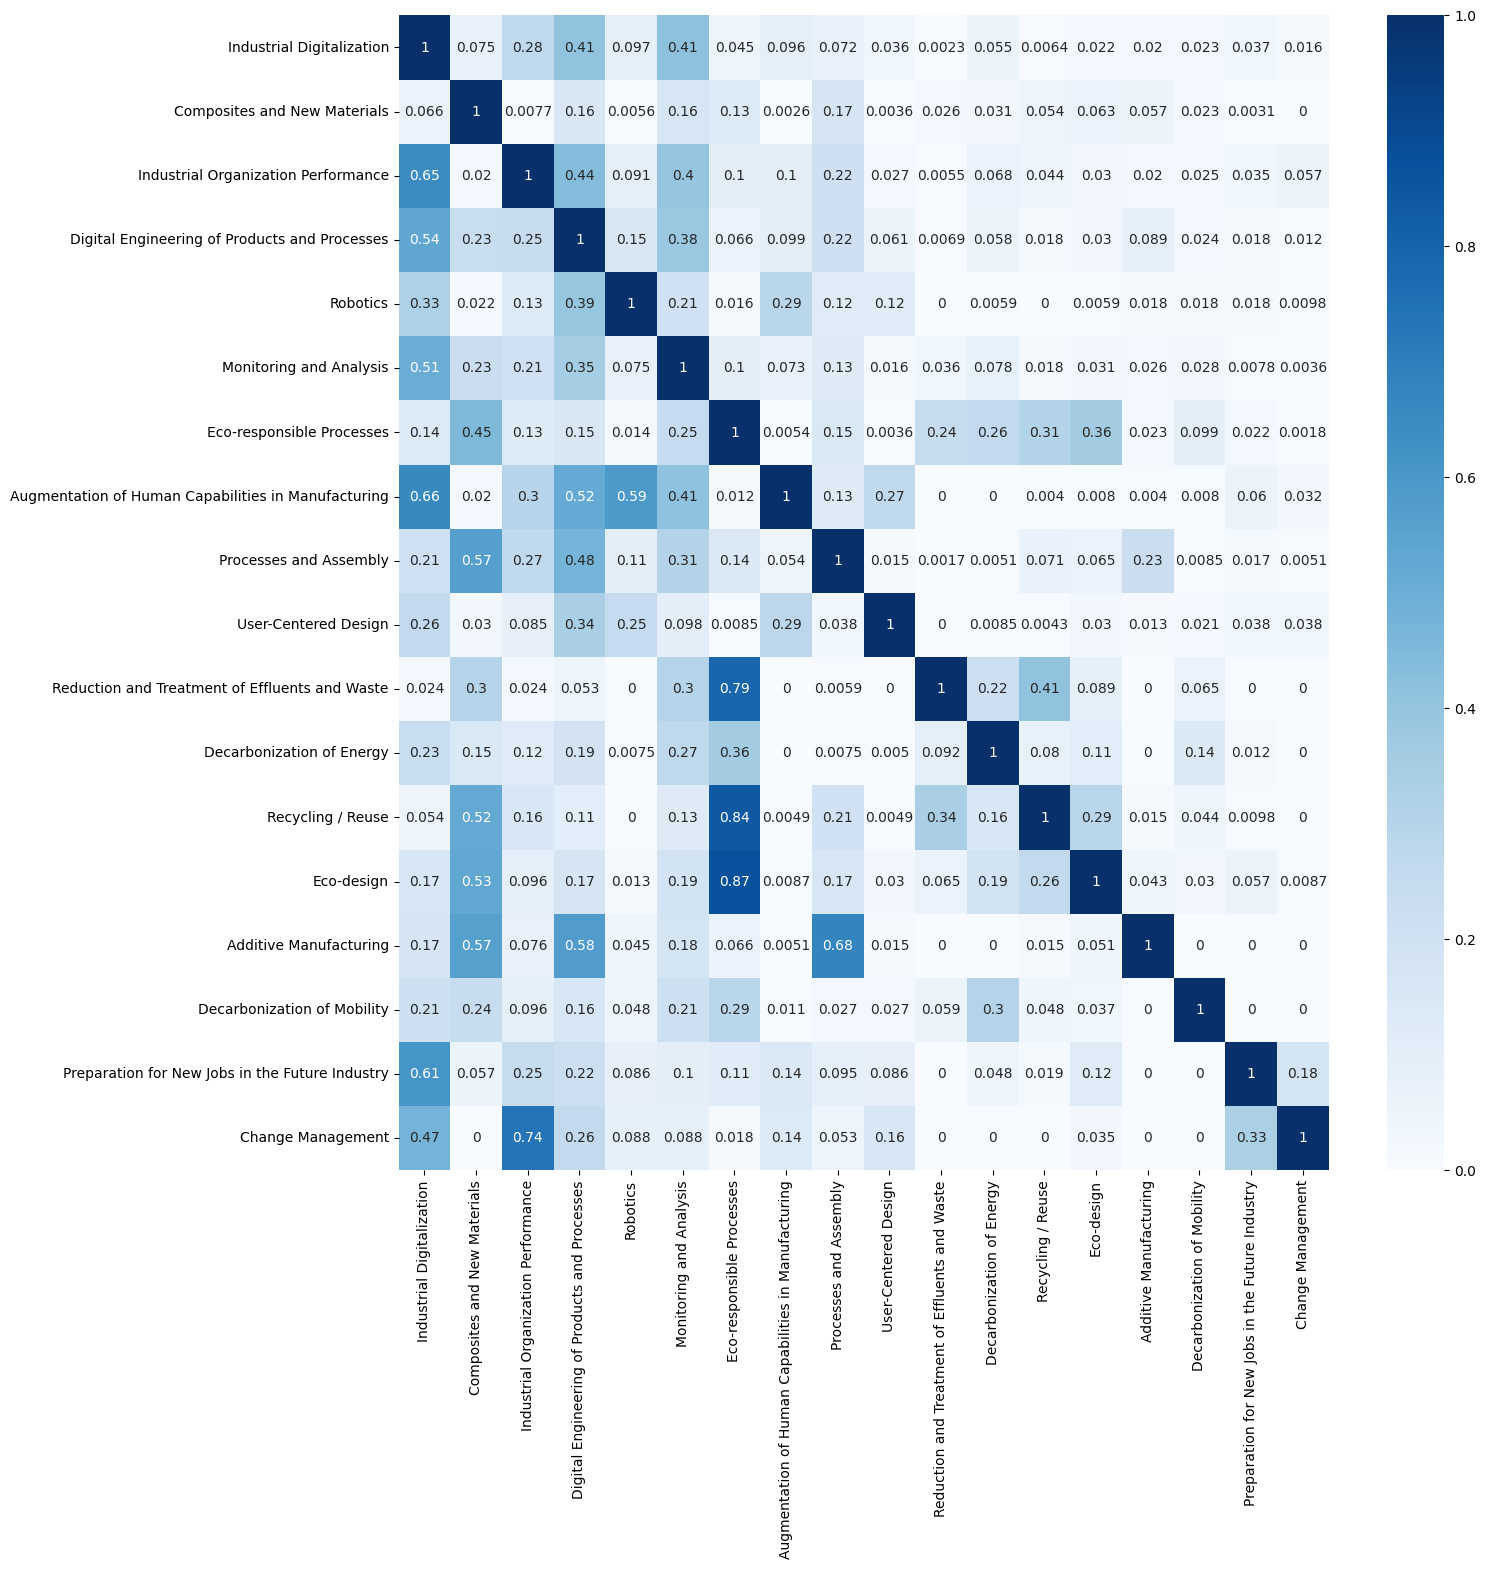

In [58]:
ax = sns.heatmap(cooccurence_matrix, cmap='Blues', annot=True)
ax.figure.set_size_inches(15, 15)